# Source selection: object and metadetect shear crossmatch (tract 9813)

Contact author: Alex Broughton

In [1]:
! eups list -s | grep lsst_distrib


lsst_distrib          gdfb3db0272+4407f27008 	current o_latest v30_0_10 v30_0_10_rc4 setup


## Introduction

Load the DRP object table and the metadetect object_shear_all table for one tract, explore g-i vs r-z color-color cuts to remove red-sequence (likely cluster member) galaxies, and crossmatch shear sources to objects on the sky. Butler paths follow _tutorials/access-dp2-metadetect-catalogs.ipynb.

## 1.0 Set Up


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pyarrow as pa
import h5py
from pathlib import Path

from astropy.coordinates import SkyCoord
from astropy import units
from lsst.daf.butler import Butler


# Repo layout: _data/ holds external inputs, output/ holds generated tables/catalogs, plots/ holds figures.
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = ROOT / "_data"
OUTPUT_DIR = ROOT / "output"
PLOTS_DIR = ROOT / "plots"
for _d in (OUTPUT_DIR, PLOTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

REPO = "/sdf/data/rubin/repo/dp2_prep"
COLLECTION = "LSSTCam/runs/DRP/DP2/v30_0_0/DM-53881/stage3"
TRACT = 9813  # COSMOS field

butler = Butler(
    REPO,
    collections=[COLLECTION],
    skymap="lsst_cells_v2",
    instrument="LSSTCam",
)

# Red-sequence veto line, g-i = slope * (r-z) + intercept, as in dp2_shearmap.ipynb.
RED_SEQ_SLOPE = 2.276
RED_SEQ_INTERCEPT = -0.20


def tract_area_deg2(skymap, tract):
    """Area of a tract's unique (inner) region in deg^2."""
    region = skymap[tract].inner_sky_region
    if hasattr(region, "getArea"):  # sphgeom.Box, as in rings skymaps
        sr = region.getArea()
    else:  # convex polygon: sum the solid angles of a triangle fan
        v = np.array([[p.x(), p.y(), p.z()] for p in region.getVertices()])
        a = v[0]
        sr = sum(
            2 * np.arctan2(abs(a @ np.cross(b, c)), 1 + a @ b + b @ c + c @ a)
            for b, c in zip(v[1:-1], v[2:])
        )
    return float(sr * (180.0 / np.pi) ** 2)


# Area of the tract's unique (inner) region, used for source densities.
skymap = butler.get("skyMap", dataId={"skymap": "lsst_cells_v2"})
TRACT_AREA_ARCMIN2 = tract_area_deg2(skymap, TRACT) * 3600.0


### Object column selection



In [3]:
columns_to_keep = [
    "u_ra",
    "g_ra",
    "r_ra",
    "i_ra",
    "z_ra",
    "y_ra",
    "u_dec",
    "g_dec",
    "r_dec",
    "i_dec",
    "z_dec",
    "y_dec",
    "u_raErr",
    "g_raErr",
    "r_raErr",
    "i_raErr",
    "z_raErr",
    "y_raErr",
    "u_decErr",
    "g_decErr",
    "r_decErr",
    "i_decErr",
    "z_decErr",
    "y_decErr",
    "u_psfFlux",
    "g_psfFlux",
    "r_psfFlux",
    "i_psfFlux",
    "z_psfFlux",
    "y_psfFlux",
    "u_psfFluxErr",
    "g_psfFluxErr",
    "r_psfFluxErr",
    "i_psfFluxErr",
    "z_psfFluxErr",
    "y_psfFluxErr",
    "u_extendedness",
    "g_extendedness",
    "r_extendedness",
    "i_extendedness",
    "z_extendedness",
    "y_extendedness",
    "u_blendedness",
    "g_blendedness",
    "r_blendedness",
    "i_blendedness",
    "z_blendedness",
    "y_blendedness",
    "u_sersicFlux",
    "g_sersicFlux",
    "r_sersicFlux",
    "i_sersicFlux",
    "z_sersicFlux",
    "y_sersicFlux",
    "u_sersicFluxErr",
    "g_sersicFluxErr",
    "r_sersicFluxErr",
    "i_sersicFluxErr",
    "z_sersicFluxErr",
    "y_sersicFluxErr",
    "u_cModelFlux",
    "g_cModelFlux",
    "r_cModelFlux",
    "i_cModelFlux",
    "z_cModelFlux",
    "y_cModelFlux",
    "u_cModelFluxErr",
    "g_cModelFluxErr",
    "r_cModelFluxErr",
    "i_cModelFluxErr",
    "z_cModelFluxErr",
    "y_cModelFluxErr",
    "u_cModel_flag",
    "g_cModel_flag",
    "r_cModel_flag",
    "i_cModel_flag",
    "z_cModel_flag",
    "y_cModel_flag",
    "u_blendedness_flag",
    "g_blendedness_flag",
    "r_blendedness_flag",
    "i_blendedness_flag",
    "z_blendedness_flag",
    "y_blendedness_flag",
    "u_pixelFlags_bad",
    "g_pixelFlags_bad",
    "r_pixelFlags_bad",
    "i_pixelFlags_bad",
    "z_pixelFlags_bad",
    "y_pixelFlags_bad",
    "u_pixelFlags_clipped",
    "g_pixelFlags_clipped",
    "r_pixelFlags_clipped",
    "i_pixelFlags_clipped",
    "z_pixelFlags_clipped",
    "y_pixelFlags_clipped",
    "u_pixelFlags_clippedCenter",
    "g_pixelFlags_clippedCenter",
    "r_pixelFlags_clippedCenter",
    "i_pixelFlags_clippedCenter",
    "z_pixelFlags_clippedCenter",
    "y_pixelFlags_clippedCenter",
    "u_pixelFlags_cr",
    "g_pixelFlags_cr",
    "r_pixelFlags_cr",
    "i_pixelFlags_cr",
    "z_pixelFlags_cr",
    "y_pixelFlags_cr",
    "u_pixelFlags_crCenter",
    "g_pixelFlags_crCenter",
    "r_pixelFlags_crCenter",
    "i_pixelFlags_crCenter",
    "z_pixelFlags_crCenter",
    "y_pixelFlags_crCenter",
    "u_pixelFlags_edge",
    "g_pixelFlags_edge",
    "r_pixelFlags_edge",
    "i_pixelFlags_edge",
    "z_pixelFlags_edge",
    "y_pixelFlags_edge",
    "u_pixelFlags_inexact_psf",
    "g_pixelFlags_inexact_psf",
    "r_pixelFlags_inexact_psf",
    "i_pixelFlags_inexact_psf",
    "z_pixelFlags_inexact_psf",
    "y_pixelFlags_inexact_psf",
    "u_pixelFlags_inexact_psfCenter",
    "g_pixelFlags_inexact_psfCenter",
    "r_pixelFlags_inexact_psfCenter",
    "i_pixelFlags_inexact_psfCenter",
    "z_pixelFlags_inexact_psfCenter",
    "y_pixelFlags_inexact_psfCenter",
    "u_pixelFlags_interpolated",
    "g_pixelFlags_interpolated",
    "r_pixelFlags_interpolated",
    "i_pixelFlags_interpolated",
    "z_pixelFlags_interpolated",
    "y_pixelFlags_interpolated",
    "u_pixelFlags_interpolatedCenter",
    "g_pixelFlags_interpolatedCenter",
    "r_pixelFlags_interpolatedCenter",
    "i_pixelFlags_interpolatedCenter",
    "z_pixelFlags_interpolatedCenter",
    "y_pixelFlags_interpolatedCenter",
    "u_pixelFlags_nodata",
    "g_pixelFlags_nodata",
    "r_pixelFlags_nodata",
    "i_pixelFlags_nodata",
    "z_pixelFlags_nodata",
    "y_pixelFlags_nodata",
    "u_pixelFlags_offimage",
    "g_pixelFlags_offimage",
    "r_pixelFlags_offimage",
    "i_pixelFlags_offimage",
    "z_pixelFlags_offimage",
    "y_pixelFlags_offimage",
    "u_pixelFlags_saturated",
    "g_pixelFlags_saturated",
    "r_pixelFlags_saturated",
    "i_pixelFlags_saturated",
    "z_pixelFlags_saturated",
    "y_pixelFlags_saturated",
    "u_pixelFlags_saturatedCenter",
    "g_pixelFlags_saturatedCenter",
    "r_pixelFlags_saturatedCenter",
    "i_pixelFlags_saturatedCenter",
    "z_pixelFlags_saturatedCenter",
    "y_pixelFlags_saturatedCenter",
    "u_pixelFlags_sensor_edge",
    "g_pixelFlags_sensor_edge",
    "r_pixelFlags_sensor_edge",
    "i_pixelFlags_sensor_edge",
    "z_pixelFlags_sensor_edge",
    "y_pixelFlags_sensor_edge",
    "u_pixelFlags_sensor_edgeCenter",
    "g_pixelFlags_sensor_edgeCenter",
    "r_pixelFlags_sensor_edgeCenter",
    "i_pixelFlags_sensor_edgeCenter",
    "z_pixelFlags_sensor_edgeCenter",
    "y_pixelFlags_sensor_edgeCenter",
    "u_pixelFlags_suspect",
    "g_pixelFlags_suspect",
    "r_pixelFlags_suspect",
    "i_pixelFlags_suspect",
    "z_pixelFlags_suspect",
    "y_pixelFlags_suspect",
    "u_pixelFlags_suspectCenter",
    "g_pixelFlags_suspectCenter",
    "r_pixelFlags_suspectCenter",
    "i_pixelFlags_suspectCenter",
    "z_pixelFlags_suspectCenter",
    "y_pixelFlags_suspectCenter",
    "u_extendedness_flag",
    "g_extendedness_flag",
    "r_extendedness_flag",
    "i_extendedness_flag",
    "z_extendedness_flag",
    "y_extendedness_flag",
    "u_invalidPsfFlag",
    "g_invalidPsfFlag",
    "r_invalidPsfFlag",
    "i_invalidPsfFlag",
    "z_invalidPsfFlag",
    "y_invalidPsfFlag",
    "u_centroid_flag",
    "g_centroid_flag",
    "r_centroid_flag",
    "i_centroid_flag",
    "z_centroid_flag",
    "y_centroid_flag",
    "parentObjectId",
    "coord_ra",
    "coord_dec",
    "coord_raErr",
    "coord_decErr",
    "coord_flag",
    "refBand",
    "refExtendedness",
    "refSizeExtendedness",
    "footprintArea",
    "ebv",
    "detect_isIsolated",
    "detect_fromBlend",
    "detect_isDeblendedModelSource",
    "deblend_peak_center_x",
    "deblend_peak_center_y",
    "deblend_chi2",
    "deblend_blendId",
    "deblend_blendNChild",
    "deblend_parentNPeaks",
    "deblend_parentNChild",
    "shape_flag",
    "g_epoch",
    "u_epoch",
    "r_epoch",
    "i_epoch",
    "z_epoch",
    "y_epoch",
    "objectId",
    "u_model_extendedness",
    "g_model_extendedness",
    "r_model_extendedness",
    "i_model_extendedness",
    "z_model_extendedness",
    "y_model_extendedness",
    "griz_model_extendedness",
]

print(len(columns_to_keep), "object columns")


246 object columns


## 2.0 Tract catalogs

Load every object ref in the tract, reading only columns_to_keep. Shear rows are restricted to the unsheared (metaStep == "ns") sources.

In [4]:
object_refs = list(
    butler.query_datasets("object", where=f"tract IN ({TRACT})")
)
print(len(object_refs), "object refs")

_get_kw = {"parameters": {"columns": columns_to_keep}}

object_table = None
for i, r in enumerate(object_refs):
    piece = butler.get(r, **_get_kw)
    object_table = piece if object_table is None else pa.concat_tables([object_table, piece])

print("object rows:", len(object_table))

shear_table = butler.get("object_shear_all", dataId={"tract": TRACT})
shear_table = shear_table[shear_table["metaStep"] == "ns"]
print("shear rows:", len(shear_table))


1 object refs
object rows: 865287
shear rows: 560011


### 2.1 Color-color plot

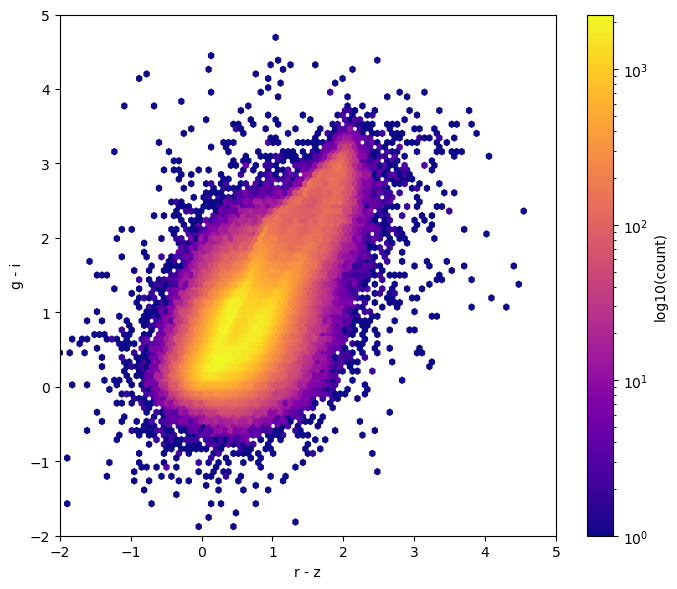

In [6]:
u = np.asarray(object_table["u_sersicFlux"], dtype=np.float64)
g = np.asarray(object_table["g_sersicFlux"], dtype=np.float64)
r = np.asarray(object_table["r_sersicFlux"], dtype=np.float64)
i = np.asarray(object_table["i_sersicFlux"], dtype=np.float64)
z = np.asarray(object_table["z_sersicFlux"], dtype=np.float64)

u_err = np.asarray(object_table["u_sersicFluxErr"], dtype=np.float64)
g_err = np.asarray(object_table["g_sersicFluxErr"], dtype=np.float64)
r_err = np.asarray(object_table["r_sersicFluxErr"], dtype=np.float64)
i_err = np.asarray(object_table["i_sersicFluxErr"], dtype=np.float64)
z_err = np.asarray(object_table["z_sersicFluxErr"], dtype=np.float64)

u_snr = u / u_err
g_snr = g / g_err
r_snr = r / r_err
i_snr = i / i_err
z_snr = z / z_err

extendedness = np.asarray(object_table["griz_model_extendedness"], dtype=np.float64)
u_blendedness = np.asarray(object_table["u_blendedness_flag"], dtype=bool)
g_blendedness = np.asarray(object_table["g_blendedness_flag"], dtype=bool)
r_blendedness = np.asarray(object_table["r_blendedness_flag"], dtype=bool)
i_blendedness = np.asarray(object_table["i_blendedness_flag"], dtype=bool)
z_blendedness = np.asarray(object_table["z_blendedness_flag"], dtype=bool)
blended = u_blendedness & g_blendedness & r_blendedness & i_blendedness & z_blendedness

# Colors from Sersic fluxes; clip to avoid log of non-positive fluxes.
tiny = np.finfo(np.float64).tiny
gi = -2.5 * np.log10(np.clip(g, tiny, None) / np.clip(i, tiny, None))
rz = -2.5 * np.log10(np.clip(r, tiny, None) / np.clip(z, tiny, None))

# Extended sources with positive flux and S/N > 3 in griz.
m = np.isfinite(gi) & np.isfinite(rz) & (extendedness > 0.2) # & ~blended 
m = m & (g > 0) & (r > 0) & (i > 0) & (z > 0)  # & (gi > -1) & (gi < 3.5) & (rz > -1) & (rz < 3.5)
m = m & (g_snr > 3) & (r_snr > 3) & (i_snr > 3) & (z_snr > 3)

plt.figure(figsize=(7, 6))
plt.hexbin(rz[m], gi[m], mincnt=1, cmap="plasma", bins="log", extent=(-2, 5, -2, 5))
plt.ylabel("g - i")
plt.xlabel("r - z")
plt.xlim(-2,5)
plt.ylim(-2,5)
plt.colorbar(label="log10(count)")
plt.tight_layout()

plt.savefig(PLOTS_DIR / "xmatch_color_color_01.pdf", bbox_inches="tight")
plt.show()

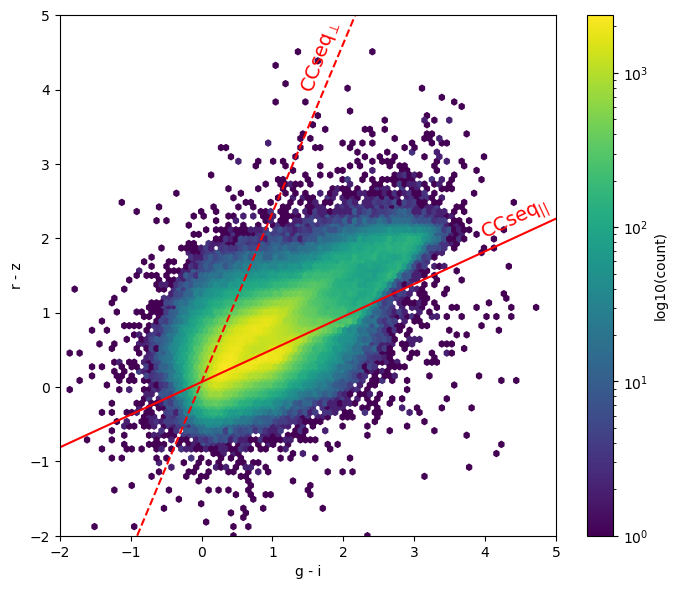

In [8]:
# Lines parallel and perpendicular to the color-color sequence.
def cc_seq_parallel(rz):
    return 2.276 * rz - 0.152

def cc_seq_perp(rz):
    return (1/2.276) * rz - 0.152/(2.276**2)

def rzseq_parallel(z):
    return -0.0248*z + 1.604

domain = np.linspace(-2, 5, 1000)

plt.figure(figsize=(7, 6))
plt.hexbin(gi[m], rz[m], mincnt=1, cmap="viridis", bins="log", extent=(-2, 5, -2, 5))
plt.plot(cc_seq_parallel(domain), domain, "r-")
plt.plot(cc_seq_perp(domain), domain, "r--")
plt.text(3.9, 2, r"CCseq||", rotation=25, color="red", fontsize=14)
plt.text(1.35, 4, r"CCseq⊥", rotation=70, color="red", fontsize=14)
plt.xlabel("g - i")
plt.ylabel("r - z")
plt.xlim(-2,5)
plt.ylim(-2,5)
plt.colorbar(label="log10(count)")
plt.tight_layout()

plt.savefig(PLOTS_DIR / "xmatch_color_color_02.pdf", bbox_inches="tight")
plt.show()

### 2.2 Template tracks and red-sequence cut

Overlay CWW+SB template color tracks (z = 0 to 5) and define the red-sequence rejection used for source selection.

In [7]:
# Template colors vs redshift for CWW+SB SEDs.
FILENAME = DATA_DIR / "CWWSB_LSST_Roman_colors_YJH.hdf5"

BAND_LIST = [
'u',
'g',
'r',
'i',
'z',
'y',
]

# Templates from Benitez (2004)
SED_list = [
    "El_B2004a",
    "Sbc_B2004a",
    "Scd_B2004a",
]

def get_redshift():
    with h5py.File(FILENAME, "r") as hf:
        redshift = hf["redshift"][:]
    return redshift

def get_color(SED_name, band1_name, band2_name):
    """Template color band1 - band2; non-adjacent bands are summed from adjacent-band colors."""
    band1_index = BAND_LIST.index(band1_name)
    band2_index = BAND_LIST.index(band2_name)

    color_name = f"{band1_name}{band2_name}"
    
    with h5py.File(FILENAME, "r") as hf:
        if (band1_index+1)==band2_index:
            color = hf[f"{SED_name}_{color_name}"][:]
        else:
            color = np.zeros_like(hf["redshift"][:])
            
            band1_name_tmp = band1_name
            while 1:
                band2_name_tmp = BAND_LIST[BAND_LIST.index(band1_name_tmp)+1]
                color_name_tmp = f"{band1_name_tmp}{band2_name_tmp}"
                color_tmp = hf[f"{SED_name}_{color_name_tmp}"][:]
                color += color_tmp
                band1_name_tmp = band2_name_tmp
                if band2_name_tmp == band2_name:
                    break
            
    return color


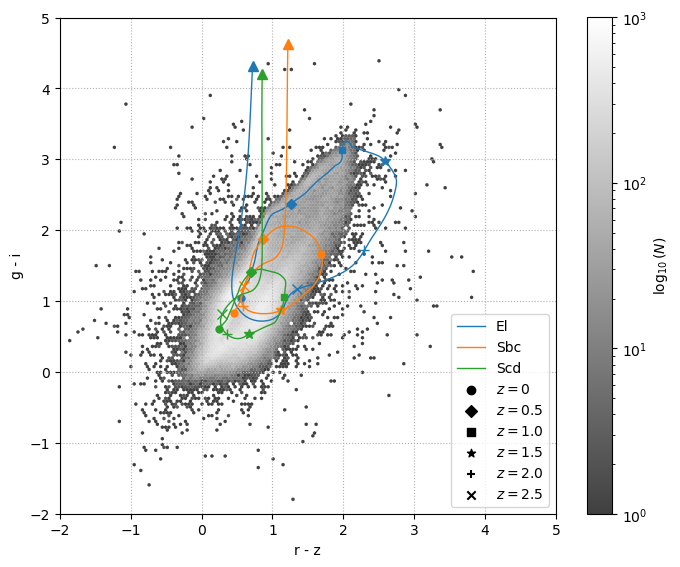

In [27]:
def make_cc_plot2(ax, SED_name, band1_name, band2_name, band3_name, band4_name, color='C0'):

    """Plot a template's color-color track, with markers at fixed redshifts."""
    alpha = 1
    redshift = get_redshift()
    sel = redshift <= 5.0
    
    color1 = get_color(SED_name, band1_name, band2_name)
    color2 = get_color(SED_name, band3_name, band4_name)

    def get_name(s):
        """Return the part of s before the first underscore."""
        return s.split('_', 1)[0]
    
    ax.plot(color1[sel], color2[sel], label=get_name(SED_name), linewidth=1, alpha=alpha)

    sel = redshift==0
    ax.plot(color1[sel], color2[sel], marker='o', markersize=5,  linestyle=None, color=color, alpha=alpha)

    sel = redshift==0.5
    ax.plot(color1[sel], color2[sel], marker='D', markersize=5, linestyle=None, color=color, alpha=alpha)

    sel = redshift==1.
    ax.plot(color1[sel], color2[sel], marker='s', markersize=5, linestyle=None, color=color, alpha=alpha)

    sel = redshift==1.5
    ax.plot(color1[sel], color2[sel], marker='*', markersize=7, linestyle=None, color=color, alpha=alpha)

    sel = redshift==2.0
    ax.plot(color1[sel], color2[sel], marker='+', markersize=7, linestyle=None, color=color, alpha=alpha)

    sel = redshift==2.5
    ax.plot(color1[sel], color2[sel], marker='x', markersize=7, linestyle=None, color=color, alpha=alpha)

    sel = redshift==5.0
    ax.plot(color1[sel], color2[sel], marker='^', markersize=7, linestyle=None, color=color, alpha=alpha)
    
    return 0


u = np.asarray(object_table["u_sersicFlux"], dtype=np.float64)
g = np.asarray(object_table["g_sersicFlux"], dtype=np.float64)
r = np.asarray(object_table["r_sersicFlux"], dtype=np.float64)
i = np.asarray(object_table["i_sersicFlux"], dtype=np.float64)
z = np.asarray(object_table["z_sersicFlux"], dtype=np.float64)

u_err = np.asarray(object_table["u_sersicFluxErr"], dtype=np.float64)
g_err = np.asarray(object_table["g_sersicFluxErr"], dtype=np.float64)
r_err = np.asarray(object_table["r_sersicFluxErr"], dtype=np.float64)
i_err = np.asarray(object_table["i_sersicFluxErr"], dtype=np.float64)
z_err = np.asarray(object_table["z_sersicFluxErr"], dtype=np.float64)

u_snr = u / u_err
g_snr = g / g_err
r_snr = r / r_err
i_snr = i / i_err
z_snr = z / z_err

extendedness = np.asarray(object_table["griz_model_extendedness"], dtype=np.float64)
u_blendedness = np.asarray(object_table["u_blendedness_flag"], dtype=bool)
g_blendedness = np.asarray(object_table["g_blendedness_flag"], dtype=bool)
r_blendedness = np.asarray(object_table["r_blendedness_flag"], dtype=bool)
i_blendedness = np.asarray(object_table["i_blendedness_flag"], dtype=bool)
z_blendedness = np.asarray(object_table["z_blendedness_flag"], dtype=bool)
blended = u_blendedness & g_blendedness & r_blendedness & i_blendedness & z_blendedness

tiny = np.finfo(np.float64).tiny
gi = -2.5 * np.log10(np.clip(g, tiny, None) / np.clip(i, tiny, None))
rz = -2.5 * np.log10(np.clip(r, tiny, None) / np.clip(z, tiny, None))

m = np.isfinite(gi) & np.isfinite(rz) & (extendedness > 0.2) # & ~blended 
m = m & (g > 0) & (r > 0) & (i > 0) & (z > 0)  # & (gi > -1) & (gi < 3.5) & (rz > -1) & (rz < 3.5)
# Same selection as 2.1 but with S/N > 10.
m = m & (g_snr > 10) & (r_snr > 10) & (i_snr > 10) & (z_snr > 10)

plt.figure(figsize=(7, 6))
plt.hexbin(rz[m], gi[m], mincnt=1, gridsize=150, cmap="binary_r", bins="log", extent=(-2, 5, -2, 5), alpha=0.75, edgecolors="none", vmin=1, vmax=1e3)
plt.colorbar(label=r"$\log_{10}(N)$", shrink=0.919)
# Overlay template tracks
ax = plt.gca()
band1_name, band2_name, band3_name, band4_name = 'r', 'z', 'g', 'i'

for ind, SED in enumerate(SED_list):
    make_cc_plot2(ax, SED, band1_name, band2_name, band3_name, band4_name, f'C{ind}')

plt.scatter([], [], marker='o', color="k", label=r"$z=0$")
plt.scatter([], [], marker='D', color="k", label=r"$z=0.5$")
plt.scatter([], [], marker='s', color="k", label=r"$z=1.0$")
plt.scatter([], [], marker='*', color="k", label=r"$z=1.5$")
plt.scatter([], [], marker='+', color="k", label=r"$z=2.0$")
plt.scatter([], [], marker='x', color="k", label=r"$z=2.5$")
plt.grid(True, ls=":")


plt.ylabel("g - i")
plt.xlabel("r - z")
plt.xlim(-2,5)
plt.ylim(-2,5)
plt.legend(loc="lower right")
plt.gca().set_aspect(1)
plt.tight_layout()

plt.savefig(PLOTS_DIR / "xmatch_color_color_03.pdf", bbox_inches="tight")
plt.show()

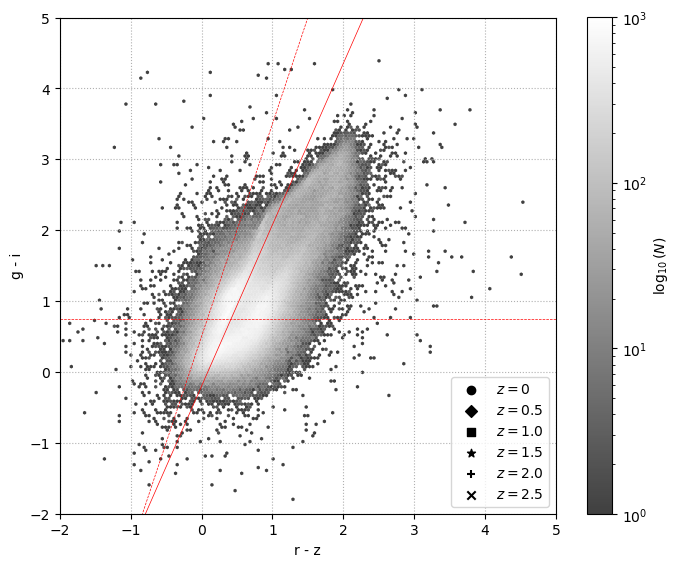

In [10]:
u = np.asarray(object_table["u_sersicFlux"], dtype=np.float64)
g = np.asarray(object_table["g_sersicFlux"], dtype=np.float64)
r = np.asarray(object_table["r_sersicFlux"], dtype=np.float64)
i = np.asarray(object_table["i_sersicFlux"], dtype=np.float64)
z = np.asarray(object_table["z_sersicFlux"], dtype=np.float64)

u_err = np.asarray(object_table["u_sersicFluxErr"], dtype=np.float64)
g_err = np.asarray(object_table["g_sersicFluxErr"], dtype=np.float64)
r_err = np.asarray(object_table["r_sersicFluxErr"], dtype=np.float64)
i_err = np.asarray(object_table["i_sersicFluxErr"], dtype=np.float64)
z_err = np.asarray(object_table["z_sersicFluxErr"], dtype=np.float64)

u_snr = u / u_err
g_snr = g / g_err
r_snr = r / r_err
i_snr = i / i_err
z_snr = z / z_err

extendedness = np.asarray(object_table["griz_model_extendedness"], dtype=np.float64)
u_blendedness = np.asarray(object_table["u_blendedness_flag"], dtype=bool)
g_blendedness = np.asarray(object_table["g_blendedness_flag"], dtype=bool)
r_blendedness = np.asarray(object_table["r_blendedness_flag"], dtype=bool)
i_blendedness = np.asarray(object_table["i_blendedness_flag"], dtype=bool)
z_blendedness = np.asarray(object_table["z_blendedness_flag"], dtype=bool)
blended = u_blendedness & g_blendedness & r_blendedness & i_blendedness & z_blendedness

tiny = np.finfo(np.float64).tiny
gi = -2.5 * np.log10(np.clip(g, tiny, None) / np.clip(i, tiny, None))
rz = -2.5 * np.log10(np.clip(r, tiny, None) / np.clip(z, tiny, None))

m = np.isfinite(gi) & np.isfinite(rz) & (extendedness > 0.2) # & ~blended 
m = m & (g > 0) & (r > 0) & (i > 0) & (z > 0)  # & (gi > -1) & (gi < 3.5) & (rz > -1) & (rz < 3.5)
# Same selection as 2.1 but with S/N > 5.
m = m & (g_snr > 5) & (r_snr > 5) & (i_snr > 5) & (z_snr > 5)

plt.figure(figsize=(7, 6))
plt.hexbin(rz[m], gi[m], mincnt=1, gridsize=150, cmap="binary_r", bins="log", extent=(-2, 5, -2, 5), alpha=0.75, edgecolors="none", vmin=1, vmax=1e3)
plt.colorbar(label=r"$\log_{10}(N)$", shrink=0.919)

# Candidate red-sequence boundary lines.
domain = np.linspace(-2, 5, 1000)
def cc_rseq_parallel1(rz):
    return RED_SEQ_SLOPE * rz + RED_SEQ_INTERCEPT

def cc_rseq_parallel2(rz):
    return 3.0 * rz + 0.5

plt.plot(domain, cc_rseq_parallel1(domain), linewidth=0.5, color="r")
plt.plot(domain, cc_rseq_parallel2(domain), linewidth=0.5, color="r", linestyle="--")
plt.axhline(0.75, linewidth=0.5, color="r", linestyle="--")

plt.scatter([], [], marker='o', color="k", label=r"$z=0$")
plt.scatter([], [], marker='D', color="k", label=r"$z=0.5$")
plt.scatter([], [], marker='s', color="k", label=r"$z=1.0$")
plt.scatter([], [], marker='*', color="k", label=r"$z=1.5$")
plt.scatter([], [], marker='+', color="k", label=r"$z=2.0$")
plt.scatter([], [], marker='x', color="k", label=r"$z=2.5$")
plt.grid(True, ls=":")


plt.ylabel("g - i")
plt.xlabel("r - z")
plt.xlim(-2,5)
plt.ylim(-2,5)
plt.legend(loc="lower right")
plt.gca().set_aspect(1)
plt.tight_layout()

plt.savefig(PLOTS_DIR / "xmatch_color_color_04.pdf", bbox_inches="tight")
plt.show()

In [11]:
def selection_function(rz, gi):
    """True for sources below the red-sequence line in g-i vs r-z."""

    def cc_rseq_parallel1(rz):
        return RED_SEQ_SLOPE * rz + RED_SEQ_INTERCEPT

    rseq = (gi > cc_rseq_parallel1(rz))
    good = ~rseq

    return good

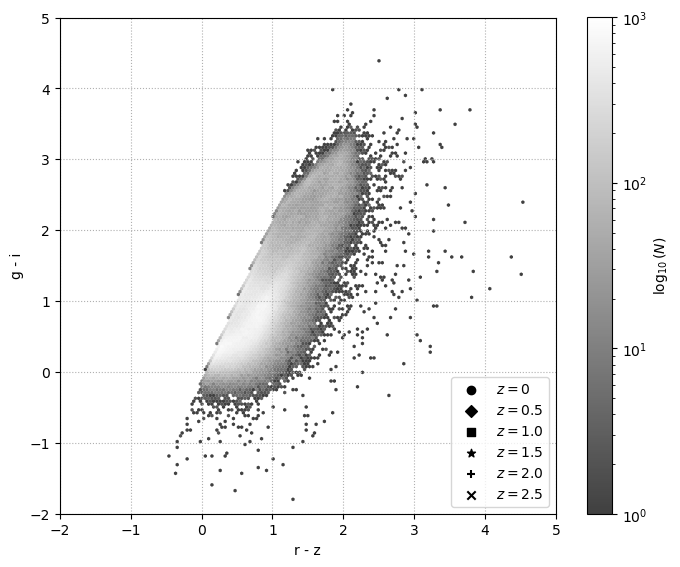

In [12]:
u = np.asarray(object_table["u_sersicFlux"], dtype=np.float64)
g = np.asarray(object_table["g_sersicFlux"], dtype=np.float64)
r = np.asarray(object_table["r_sersicFlux"], dtype=np.float64)
i = np.asarray(object_table["i_sersicFlux"], dtype=np.float64)
z = np.asarray(object_table["z_sersicFlux"], dtype=np.float64)

u_err = np.asarray(object_table["u_sersicFluxErr"], dtype=np.float64)
g_err = np.asarray(object_table["g_sersicFluxErr"], dtype=np.float64)
r_err = np.asarray(object_table["r_sersicFluxErr"], dtype=np.float64)
i_err = np.asarray(object_table["i_sersicFluxErr"], dtype=np.float64)
z_err = np.asarray(object_table["z_sersicFluxErr"], dtype=np.float64)

u_snr = u / u_err
g_snr = g / g_err
r_snr = r / r_err
i_snr = i / i_err
z_snr = z / z_err

extendedness = np.asarray(object_table["griz_model_extendedness"], dtype=np.float64)
u_blendedness = np.asarray(object_table["u_blendedness_flag"], dtype=bool)
g_blendedness = np.asarray(object_table["g_blendedness_flag"], dtype=bool)
r_blendedness = np.asarray(object_table["r_blendedness_flag"], dtype=bool)
i_blendedness = np.asarray(object_table["i_blendedness_flag"], dtype=bool)
z_blendedness = np.asarray(object_table["z_blendedness_flag"], dtype=bool)
blended = u_blendedness & g_blendedness & r_blendedness & i_blendedness & z_blendedness

tiny = np.finfo(np.float64).tiny
gi = -2.5 * np.log10(np.clip(g, tiny, None) / np.clip(i, tiny, None))
rz = -2.5 * np.log10(np.clip(r, tiny, None) / np.clip(z, tiny, None))

m = np.isfinite(gi) & np.isfinite(rz) & (extendedness > 0.2) # & ~blended 
m = m & (g > 0) & (r > 0) & (i > 0) & (z > 0)  # & (gi > -1) & (gi < 3.5) & (rz > -1) & (rz < 3.5)
m = m & (g_snr > 5) & (r_snr > 5) & (i_snr > 5) & (z_snr > 5)
# S/N > 5 plus the red-sequence rejection.
m = m & selection_function(rz, gi)

plt.figure(figsize=(7, 6))
plt.hexbin(rz[m], gi[m], mincnt=1, gridsize=150, cmap="binary_r", bins="log", extent=(-2, 5, -2, 5), alpha=0.75, edgecolors="none", vmin=1, vmax=1e3)
plt.colorbar(label=r"$\log_{10}(N)$", shrink=0.919)

plt.scatter([], [], marker='o', color="k", label=r"$z=0$")
plt.scatter([], [], marker='D', color="k", label=r"$z=0.5$")
plt.scatter([], [], marker='s', color="k", label=r"$z=1.0$")
plt.scatter([], [], marker='*', color="k", label=r"$z=1.5$")
plt.scatter([], [], marker='+', color="k", label=r"$z=2.0$")
plt.scatter([], [], marker='x', color="k", label=r"$z=2.5$")
plt.grid(True, ls=":")


plt.ylabel("g - i")
plt.xlabel("r - z")
plt.xlim(-2,5)
plt.ylim(-2,5)
plt.legend(loc="lower right")
plt.gca().set_aspect(1)
plt.tight_layout()

plt.savefig(PLOTS_DIR / "xmatch_color_color_05.pdf", bbox_inches="tight")
plt.show()

## 3.0 Crossmatch (object to shear)

Match each metadetect shear source to its nearest DRP object on the sky and keep the objects that have a shear match within 0.2 arcsec.

In [13]:
MATCH_RADIUS = 0.2 * units.arcsecond

obj_coords = SkyCoord(
    ra=np.asarray(object_table["coord_ra"]) * units.deg,
    dec=np.asarray(object_table["coord_dec"]) * units.deg,
)

_shear_names = (
    list(shear_table.schema.names)
    if hasattr(shear_table, "schema")
    else list(shear_table.colnames)
)
if "ra" in _shear_names and "dec" in _shear_names:
    _sh_ra, _sh_dec = "ra", "dec"
elif "coord_ra" in _shear_names and "coord_dec" in _shear_names:
    _sh_ra, _sh_dec = "coord_ra", "coord_dec"
else:
    raise KeyError(f"No sky position columns in shear table: {_shear_names[:20]}")

shear_coords = SkyCoord(
    ra=np.asarray(shear_table[_sh_ra]) * units.deg,
    dec=np.asarray(shear_table[_sh_dec]) * units.deg,
)

# Nearest object per shear row; keep shear with a match inside the radius.
obj_idx, sep, _ = shear_coords.match_to_catalog_sky(obj_coords)
shear_xmatch = sep < MATCH_RADIUS
object_xmatch = np.zeros(len(object_table), dtype=bool)
object_xmatch[obj_idx[shear_xmatch]] = True

object_table_xmatch = object_table[object_xmatch]

print(f"match radius: {MATCH_RADIUS.to(units.mas):.3f}")
print(f"object rows:           {len(object_table):,}")
print(f"shear rows:            {len(shear_table):,}")
print(f"shear with object match: {int(shear_xmatch.sum()):,}")
print(f"objects with shear match: {int(object_xmatch.sum()):,}")
print(f"object_table_xmatch:   {len(object_table_xmatch):,}")

match radius: 200.000 mas
object rows:           865,287
shear rows:            560,011
shear with object match: 370,083
objects with shear match: 305,967
object_table_xmatch:   305,967
shear_table_xmatch:    370,083


## 3.1 Apply the color-color selection to the matched objects

In [15]:
def get_c(obj_table):
    u = np.asarray(obj_table["u_sersicFlux"], dtype=np.float64)
    g = np.asarray(obj_table["g_sersicFlux"], dtype=np.float64)
    r = np.asarray(obj_table["r_sersicFlux"], dtype=np.float64)
    i = np.asarray(obj_table["i_sersicFlux"], dtype=np.float64)
    z = np.asarray(obj_table["z_sersicFlux"], dtype=np.float64)
    
    u_err = np.asarray(obj_table["u_sersicFluxErr"], dtype=np.float64)
    g_err = np.asarray(obj_table["g_sersicFluxErr"], dtype=np.float64)
    r_err = np.asarray(obj_table["r_sersicFluxErr"], dtype=np.float64)
    i_err = np.asarray(obj_table["i_sersicFluxErr"], dtype=np.float64)
    z_err = np.asarray(obj_table["z_sersicFluxErr"], dtype=np.float64)

    return u, g, r, i, z, u_err, g_err, r_err, i_err, z_err

def get_cc(obj_table):
    u, g, r, i, z, u_err, g_err, r_err, i_err, z_err = get_c(obj_table)
    
    u_snr = u / u_err
    g_snr = g / g_err
    r_snr = r / r_err
    i_snr = i / i_err
    z_snr = z / z_err
    
    tiny = np.finfo(np.float64).tiny
    gi = -2.5 * np.log10(np.clip(g, tiny, None) / np.clip(i, tiny, None))
    rz = -2.5 * np.log10(np.clip(r, tiny, None) / np.clip(z, tiny, None))

    return gi, rz

def get_selection_function(obj_table):
    u, g, r, i, z, u_err, g_err, r_err, i_err, z_err = get_c(obj_table)

    gi, rz = get_cc(obj_table)

    u_snr = u / u_err
    g_snr = g / g_err
    r_snr = r / r_err
    i_snr = i / i_err
    z_snr = z / z_err
    
    extendedness = np.asarray(obj_table["griz_model_extendedness"], dtype=np.float64)
    u_blendedness = np.asarray(obj_table["u_blendedness_flag"], dtype=bool)
    g_blendedness = np.asarray(obj_table["g_blendedness_flag"], dtype=bool)
    r_blendedness = np.asarray(obj_table["r_blendedness_flag"], dtype=bool)
    i_blendedness = np.asarray(obj_table["i_blendedness_flag"], dtype=bool)
    z_blendedness = np.asarray(obj_table["z_blendedness_flag"], dtype=bool)
    blended = u_blendedness & g_blendedness & r_blendedness & i_blendedness & z_blendedness
    
    
    
    m = np.isfinite(gi) & np.isfinite(rz) & (extendedness > 0.2) # & ~blended 
    m = m & (g > 0) & (r > 0) & (i > 0) & (z > 0)  # & (gi > -1) & (gi < 3.5) & (rz > -1) & (rz < 3.5)
    m = m & (g_snr > 5) & (r_snr > 5) & (i_snr > 5) & (z_snr > 5)
    m = m & selection_function(rz, gi)

    return m
    

In [ ]:
gi, rz = get_cc(object_table_xmatch)
gold = get_selection_function(object_table_xmatch)

print("N_gal / arcmin^2 ~", round(float(np.count_nonzero(gold) / TRACT_AREA_ARCMIN2), 3))

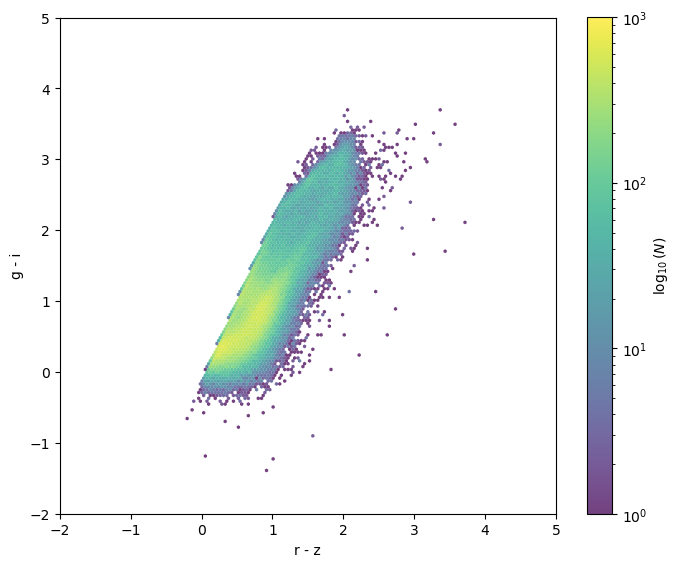

In [18]:
plt.figure(figsize=(7, 6))
plt.hexbin(rz[gold], gi[gold], mincnt=1, gridsize=150, cmap="viridis", bins="log", extent=(-2, 5, -2, 5), alpha=0.75, edgecolors="none", vmin=1, vmax=1e3)
plt.colorbar(label=r"log10⁡(N)", shrink=0.919)

plt.ylabel("g - i")
plt.xlabel("r - z")
plt.xlim(-2,5)
plt.ylim(-2,5)
plt.gca().set_aspect(1)
plt.tight_layout()


plt.savefig(PLOTS_DIR / "xmatch_color_color_06.pdf", bbox_inches="tight")
plt.show()